In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

In [2]:
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")

IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Dataset exists:", DATA_DIR.exists())
print(
    "GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
)

Device: cuda
Dataset exists: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
class SimCLRTransform:
    def __init__(self, size=224):
        self.transform = transforms.Compose(
            [
                transforms.RandomResizedCrop(
                    size,
                    scale=(0.7, 1.0),
                    ratio=(0.9, 1.1),
                    interpolation=InterpolationMode.BICUBIC,
                ),
                transforms.RandomHorizontalFlip(),
                transforms.RandomVerticalFlip(),
                transforms.RandomApply(
                    [
                        transforms.ColorJitter(
                            brightness=0.2,
                            contrast=0.2,
                            saturation=0.1,
                            hue=0.02,
                        )
                    ],
                    p=0.5,
                ),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=(0.485, 0.456, 0.406),
                    std=(0.229, 0.224, 0.225),
                ),
            ]
        )

    def __call__(self, image):
        view1 = self.transform(image)
        view2 = self.transform(image)
        return view1, view2

In [4]:
class AirbusSimCLRDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = Path(image_dir)
        self.image_paths = sorted(self.image_dir.glob("*.jpg"))
        self.transform = transform

        if not self.image_paths:
            raise RuntimeError(
                f"No JPG images found in {self.image_dir.resolve()}"
            )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")

        if self.transform is not None:
            return self.transform(image)

        return transforms.ToTensor()(image)

In [5]:
simclr_dataset = AirbusSimCLRDataset(
    DATA_DIR,
    transform=SimCLRTransform(IMAGE_SIZE),
)

print("Number of images:", len(simclr_dataset))

view1, view2 = simclr_dataset[0]

print("View 1 shape:", view1.shape)
print("View 2 shape:", view2.shape)

Number of images: 192556
View 1 shape: torch.Size([3, 224, 224])
View 2 shape: torch.Size([3, 224, 224])


In [6]:
def show_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = tensor.cpu() * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0)

    return image.numpy()

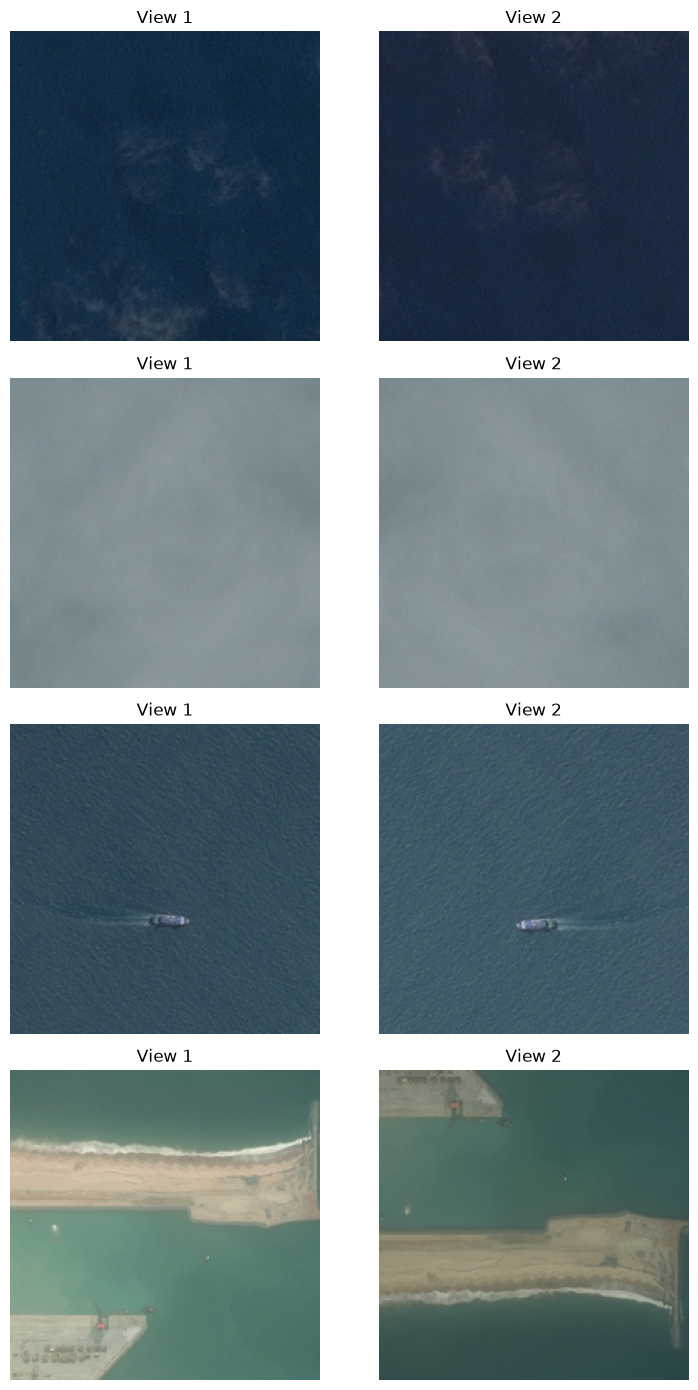

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(8, 14))

for row in range(4):
    view1, view2 = simclr_dataset[row]

    axes[row, 0].imshow(show_image(view1))
    axes[row, 0].set_title("View 1")

    axes[row, 1].imshow(show_image(view2))
    axes[row, 1].set_title("View 2")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18

In [9]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        backbone = resnet18(weights=None)

        # Replace the classification layer with an identity.
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim),
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)

        # Normalize projections for contrastive learning.
        projections = F.normalize(projections, dim=1)

        return features, projections

In [10]:
model = SimCLR().to(DEVICE)

print("Model initialized on:", DEVICE)
print(
    "Encoder feature dimension:",
    model.encoder.fc.in_features
    if isinstance(model.encoder.fc, nn.Linear)
    else 512,
)

Model initialized on: cuda
Encoder feature dimension: 512


In [11]:
def nt_xent_loss(z1, z2, temperature=0.5):
    """
    z1, z2: normalized projection tensors of shape (B, D).
    """
    batch_size = z1.size(0)

    if z2.shape != z1.shape:
        raise ValueError("Both views must have matching shapes.")

    if batch_size < 2:
        raise ValueError("NT-Xent requires a batch size of at least 2.")

    # Arrange projections as [view1 batch, view2 batch].
    z = torch.cat([z1, z2], dim=0)

    # Pairwise cosine similarities because projections are normalized.
    logits = torch.matmul(z, z.T) / temperature

    # Exclude self-similarity from the candidate set.
    logits.fill_diagonal_(float("-inf"))

    # Positive for sample i is the corresponding sample in the other view.
    labels = torch.cat(
        [
            torch.arange(batch_size, 2 * batch_size, device=z.device),
            torch.arange(0, batch_size, device=z.device),
        ]
    )

    return F.cross_entropy(logits, labels)

In [12]:
model.train()
model.zero_grad(set_to_none=True)

batch_size = 8

x1 = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
x2 = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)

features1, z1 = model(x1)
features2, z2 = model(x2)

loss = nt_xent_loss(z1, z2)

loss.backward()

In [13]:
print("Features:", features1.shape)
print("Projections:", z1.shape)
print("Loss:", loss.item())
print("Backward pass: successful")

Features: torch.Size([8, 512])
Projections: torch.Size([8, 128])
Loss: 2.7064645290374756
Backward pass: successful


In [14]:
del x1, x2, features1, features2, z1, z2, loss
model.zero_grad(set_to_none=True)

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

In [15]:
import time
from pathlib import Path

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 4

train_loader = DataLoader(
    simclr_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Images:", len(simclr_dataset))
print("Batches per epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)

Images: 192556
Batches per epoch: 6017
Batch size: 32


In [16]:
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
TEMPERATURE = 0.5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

use_amp = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp,
)

print("Mixed precision:", use_amp)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)

Mixed precision: True
Optimizer: AdamW
Learning rate: 0.0003


In [17]:
def train_one_epoch(model, loader, optimizer, scaler, max_steps=None):
    model.train()

    total_loss = 0.0
    total_samples = 0
    start_time = time.time()

    for step, (view1, view2) in enumerate(loader):
        if max_steps is not None and step >= max_steps:
            break

        view1 = view1.to(DEVICE, non_blocking=True)
        view2 = view2.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp,
        ):
            _, z1 = model(view1)
            _, z2 = model(view2)

        # Compute contrastive loss in FP32.
        loss = nt_xent_loss(
            z1.float(),
            z2.float(),
            temperature=TEMPERATURE,
        )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_samples = view1.size(0)
        total_loss += loss.item() * batch_samples
        total_samples += batch_samples

        if (step + 1) % 25 == 0:
            avg_loss = total_loss / total_samples
            elapsed = time.time() - start_time

            print(
                f"Step {step + 1} | "
                f"Avg loss: {avg_loss:.4f} | "
                f"Elapsed: {elapsed / 60:.1f} min"
            )

    elapsed = time.time() - start_time
    avg_loss = total_loss / total_samples if total_samples else float("nan")

    if DEVICE.type == "cuda":
        peak_memory = torch.cuda.max_memory_allocated() / 1024**3
        print(f"Peak GPU memory allocated: {peak_memory:.2f} GiB")

    return {
        "average_loss": avg_loss,
        "steps": step + 1 if total_samples else 0,
        "elapsed_seconds": elapsed,
    }

In [18]:
from pathlib import Path

CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = CHECKPOINT_DIR / "simclr_trial.pt"

In [19]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "config": {
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "projection_dim": 128,
            "temperature": TEMPERATURE,
            "learning_rate": LEARNING_RATE,
        },
    },
    checkpoint_path,
)

print("Checkpoint saved to:", checkpoint_path.resolve())

Checkpoint saved to: /home/abhi/Dev/varuna-ssl/checkpoints/simclr_trial.pt


In [20]:
history = []

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

result = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    scaler=scaler,
    max_steps=100,
)

history.append(result)

print("\nTrial results")
print("Steps:", result["steps"])
print(f"Average loss: {result['average_loss']:.4f}")
print(f"Duration: {result['elapsed_seconds'] / 60:.2f} minutes")

Step 25 | Avg loss: 2.7383 | Elapsed: 0.1 min
Step 50 | Avg loss: 2.6429 | Elapsed: 0.1 min
Step 75 | Avg loss: 2.6048 | Elapsed: 0.2 min
Step 100 | Avg loss: 2.5821 | Elapsed: 0.3 min
Peak GPU memory allocated: 0.94 GiB

Trial results
Steps: 101
Average loss: 2.5821
Duration: 0.26 minutes


In [21]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "config": {
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "projection_dim": 128,
            "temperature": TEMPERATURE,
            "learning_rate": LEARNING_RATE,
        },
        "history": history,
    },
    checkpoint_path,
)

print("Saved:", checkpoint_path.resolve())

Saved: /home/abhi/Dev/varuna-ssl/checkpoints/simclr_trial.pt


In [22]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [23]:
from pathlib import Path

bad_images = []

for i, path in enumerate(simclr_dataset.image_paths):
    try:
        with Image.open(path) as img:
            img.verify()

        # verify() checks file structure; load() checks actual decoding.
        with Image.open(path) as img:
            img.load()

    except Exception as e:
        bad_images.append(path)
        print(f"Unreadable: {path.name} — {e}")

print(f"\nUnreadable images: {len(bad_images)}")


Unreadable images: 0


In [24]:
train_loader = DataLoader(
    simclr_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 6017


In [25]:
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

result = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    scaler=scaler,
)

history.append(result)

print("\nEpoch results")
print("Steps:", result["steps"])
print(f"Average loss: {result['average_loss']:.4f}")
print(f"Duration: {result['elapsed_seconds'] / 60:.2f} minutes")

Step 25 | Avg loss: 2.4770 | Elapsed: 0.1 min
Step 50 | Avg loss: 2.4874 | Elapsed: 0.1 min
Step 75 | Avg loss: 2.4858 | Elapsed: 0.2 min
Step 100 | Avg loss: 2.4804 | Elapsed: 0.2 min
Step 125 | Avg loss: 2.4756 | Elapsed: 0.3 min
Step 150 | Avg loss: 2.4728 | Elapsed: 0.4 min
Step 175 | Avg loss: 2.4651 | Elapsed: 0.4 min
Step 200 | Avg loss: 2.4617 | Elapsed: 0.5 min
Step 225 | Avg loss: 2.4600 | Elapsed: 0.5 min
Step 250 | Avg loss: 2.4574 | Elapsed: 0.6 min
Step 275 | Avg loss: 2.4535 | Elapsed: 0.7 min
Step 300 | Avg loss: 2.4498 | Elapsed: 0.7 min
Step 325 | Avg loss: 2.4457 | Elapsed: 0.8 min
Step 350 | Avg loss: 2.4426 | Elapsed: 0.8 min
Step 375 | Avg loss: 2.4390 | Elapsed: 0.9 min
Step 400 | Avg loss: 2.4366 | Elapsed: 1.0 min
Step 425 | Avg loss: 2.4345 | Elapsed: 1.0 min
Step 450 | Avg loss: 2.4332 | Elapsed: 1.1 min
Step 475 | Avg loss: 2.4319 | Elapsed: 1.1 min
Step 500 | Avg loss: 2.4301 | Elapsed: 1.2 min
Step 525 | Avg loss: 2.4296 | Elapsed: 1.2 min
Step 550 | Avg l

In [26]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "config": {
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "projection_dim": 128,
            "temperature": TEMPERATURE,
            "learning_rate": LEARNING_RATE,
        },
        "history": history,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path.resolve())
print("Training records:", len(history))

Checkpoint saved: /home/abhi/Dev/varuna-ssl/checkpoints/simclr_trial.pt
Training records: 2
